# Depression Analysis in the U.S.

## About
Statistical analysis focusing on depression rate in the U.S. Least squares regression was run on other chronic disease indicators to measure level of influence from obesity, poverty, sleeplessness, inactivity, and regular checkups on depression on a state by state level.

## Data
CDC U.S. Chronic Disease Indicators (2019-2023)
The regression uses 2022 data for the 50 states.

## Key Findings
- Together, the five predictors explain about 25% of the variation in depression between states (adj. R² = 0.25, F-test p = 0.003).
- Obesity (β = 0.51, p = 0.004) and poverty (β = 0.48, p = 0.018) are statistically significant positive predictors of depression on a state by state level in 2022.
- Checkup rates and sleeplessness are not statistically significant predictors.
- On a nationwide level depression rate in 2022 varied drastically by sex (Male = 15.2 Female = 26.9) and race (Asian non-Hispanic = 9.9 Multiracial non-Hispanic = 30.6).
- Model diagnostics support regression assumptions. Results were consistent when most influential states were removed.

## Limitations
- This is an observational analysis of state and national data. It shows only correlation, not causation and it cannot be used to make estimates about individuals.
- Results show inactivity is a significant negative predictor of depression. This is likely due to its strong correlation with poverty (r = 0.80) and obesity (r = 0.72).

In [1]:
#Importing necessary libraries for analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

## Exploring Data

In [2]:
#Importing the data into the code
disease = pd.read_csv("chronic_disease.csv", low_memory=False)

In [3]:
#Getting an idea of how much data we are working with
disease.shape

(398793, 34)

In [4]:
#Just exploring the data
disease.head(15)

,YearStart,YearEnd,LocationAbbr,LocationDesc,DataSource,Topic,Question,Response,DataValueUnit,DataValueType,...,TopicID,QuestionID,ResponseID,DataValueTypeID,StratificationCategoryID1,StratificationID1,StratificationCategoryID2,StratificationID2,StratificationCategoryID3,StratificationID3
0,2020,2020,AR,Arkansas,NVSS,Asthma,"Asthma mortality among all people, underlying ...",NaN,Number,Number,...,AST,AST01,NaN,NMBR,SEX,SEXF,NaN,NaN,NaN,NaN
1,2019,2019,IA,Iowa,NVSS,Asthma,"Asthma mortality among all people, underlying ...",NaN,Number,Number,...,AST,AST01,NaN,NMBR,SEX,SEXF,NaN,NaN,NaN,NaN
2,2021,2021,CO,Colorado,BRFSS,Asthma,Current asthma among adults,NaN,%,Crude Prevalence,...,AST,AST02,NaN,CRDPREV,SEX,SEXM,NaN,NaN,NaN,NaN
3,2023,2023,KY,Kentucky,BRFSS,Asthma,Current asthma among adults,NaN,%,Crude Prevalence,...,AST,AST02,NaN,CRDPREV,AGE,AGE65P,NaN,NaN,NaN,NaN
4,2023,2023,MD,Maryland,BRFSS,Asthma,Current asthma among adults,NaN,%,Crude Prevalence,...,AST,AST02,NaN,CRDPREV,AGE,AGE65P,NaN,NaN,NaN,NaN
5,2015,2019,VA,Virginia,US Cancer DVT,Cancer,"Invasive cancer (all sites combined), incidence",NaN,Number,Number,...,CAN,CAN07,NaN,NMBR,SEX,SEXM,NaN,NaN,NaN,NaN
6,2017,2021,CO,Colorado,US Cancer DVT,Cancer,Invasive cancer (all sites combined) mortality...,NaN,Number,Number,...,CAN,CAN08,NaN,NMBR,SEX,SEXF,NaN,NaN,NaN,NaN
7,2016,2020,NV,Nevada,US Cancer DVT,Cancer,Invasive cancer (all sites combined) mortality...,NaN,Number,Number,...,CAN,CAN08,NaN,NMBR,SEX,SEXF,NaN,NaN,NaN,NaN
8,2017,2021,WI,Wisconsin,US Cancer DVT,Cancer,Invasive cancer (all sites combined) mortality...,NaN,Number,Number,...,CAN,CAN08,NaN,NMBR,OVERALL,OVR,NaN,NaN,NaN,NaN
9,2020,2020,US,United States,BRFSS,Cancer,Mammography use among women aged 50-74 years,NaN,%,Crude Prevalence,...,CAN,CAN09,NaN,CRDPREV,RACE,WHT,NaN,NaN,NaN,NaN


In [5]:
#Setting the display to 100 so I can see the output I want. Also changing column headers to lowercase to make calling them easier.
pd.set_option('display.max_rows', 100)
disease.columns = disease.columns.str.lower()

In [6]:
#Checking what years the data covers
print(disease.yearend.value_counts())

yearend
2019    94191
2021    93266
2020    79961
2022    76189
2023    55186
Name: count, dtype: int64


In [7]:
#Checking location of data
print(disease.locationabbr.value_counts())

locationabbr
US    7479
SD    7451
CO    7445
UT    7445
MA    7445
NE    7445
MO    7445
PA    7445
HI    7445
KS    7445
VT    7445
AL    7445
ND    7445
CT    7445
MI    7445
NM    7437
MT    7437
VA    7403
NY    7403
ME    7403
NJ    7403
AR    7396
KY    7396
GA    7396
LA    7396
MS    7396
TN    7396
IL    7396
WY    7389
WA    7389
WI    7375
DE    7361
DC    7361
IA    7347
MD    7347
OK    7347
FL    7347
WV    7347
RI    7347
OR    7340
MN    7340
AZ    7339
AK    7325
NC    7298
NH    7263
SC    7263
ID    7249
OH    7249
TX    7249
NV    7221
CA    7207
IN    7193
PR    5317
GU    5019
VI    4991
Name: count, dtype: int64


In [8]:
#Browsing through the available topics
print(disease.topic.value_counts())

topic
Cardiovascular Disease                             42636
Chronic Obstructive Pulmonary Disease              36778
Alcohol                                            32913
Nutrition, Physical Activity, and Weight Status    32712
Health Status                                      32093
Non-Medical Factors                                27507
Cancer                                             27432
Arthritis                                          25190
Immunization                                       23925
Diabetes                                           22599
Mental Health                                      21883
Tobacco                                            21153
Asthma                                             13813
Oral Health                                        13508
Cognitive Health and Caregiving                     9900
Sleep                                               6712
Disability                                          6325
Maternal Health          

In [9]:
#Browsing through the more specific question column
print(disease.question.value_counts())

question
Asthma mortality among all people, underlying cause                              7488
Coronary heart disease mortality among all people, underlying cause              7488
Chronic liver disease mortality among all people, underlying cause               7488
Cerebrovascular disease (stroke) mortality among all people, underlying cause    7488
Diseases of the heart mortality among all people, underlying cause               7488
                                                                                 ... 
Per capita alcohol consumption among people aged 14 years and older               220
Infants who were breastfed at 12 months                                           184
Infants who were exclusively breastfed through 6 months                           184
No broadband internet subscription among households                               156
Food insecure in the past 12 months among households                              110
Name: count, Length: 108, dtype: int64


In [10]:
#Checking the data footnote column
print(disease.datavaluefootnote.value_counts())

datavaluefootnote
Data suppressed; denominator < 50 or relative standard error > 30%                                                      66555
Data suppressed; too few respondents or cases                                                                           36607
No data available                                                                                                       16381
No data available for this indicator because the module was not used by the state or territory                           7109
Interpret with caution: 95% confidence interval width is greater than 20 percentage points or 1.2 times the estimate     1140
Interpret with caution; less than 60 respondents                                                                          705
Estimate is 0.0% because no cases were reported with this condition                                                       148
The state registry opted not to present state-specific estimates for this race/ethnicity group      

# Data Cleaning

In [11]:
#Checking the data value type column
print(disease.datavaluetype.value_counts())

datavaluetype
Crude Prevalence                                 165341
Age-adjusted Prevalence                           93830
Number                                            37412
Crude Rate                                        36736
Age-adjusted Rate                                 31536
Crude Mean                                        10725
Age-adjusted Mean                                  8250
Crude Median                                       7150
Crude 75th percentile                              7110
Proportion                                          275
Per capita alcohol consumption gallons              220
Adjusted rate by age, sex, race and ethnicity       208
Name: count, dtype: int64


In [12]:
#Checking missing data and missing data percentage
print(len(disease[pd.isnull(disease.datavalue)])/len(disease))
disease[pd.isnull(disease.datavalue)].head()

0.31785161725506716


,yearstart,yearend,locationabbr,locationdesc,datasource,topic,question,response,datavalueunit,datavaluetype,...,topicid,questionid,responseid,datavaluetypeid,stratificationcategoryid1,stratificationid1,stratificationcategoryid2,stratificationid2,stratificationcategoryid3,stratificationid3
3,2023,2023,KY,Kentucky,BRFSS,Asthma,Current asthma among adults,NaN,%,Crude Prevalence,...,AST,AST02,NaN,CRDPREV,AGE,AGE65P,NaN,NaN,NaN,NaN
18,2021,2021,FL,Florida,BRFSS,Disability,Adults with any disability,NaN,%,Crude Prevalence,...,DIS,DIS01,NaN,CRDPREV,SEX,SEXM,NaN,NaN,NaN,NaN
20,2023,2023,KY,Kentucky,BRFSS,Disability,Adults with any disability,NaN,%,Crude Prevalence,...,DIS,DIS01,NaN,CRDPREV,SEX,SEXM,NaN,NaN,NaN,NaN
36,2021,2021,GU,Guam,YRBSS,Alcohol,Alcohol use among high school students,NaN,%,Crude Prevalence,...,ALC,ALC01,NaN,CRDPREV,GRADE,GRD12,NaN,NaN,NaN,NaN
37,2019,2019,WV,West Virginia,BRFSS,Alcohol,Binge drinking frequency among adults who bing...,NaN,Number,Crude Median,...,ALC,ALC04,NaN,CRDMEDN,RACE,MRC,NaN,NaN,NaN,NaN


In [13]:
#Dropping unneeded columns
disease = disease.drop(columns=['datavaluefootnotesymbol', 'stratificationcategory2', 'stratification2',  'stratificationcategory3',
'stratification3', 'locationid', 'topicid', 'questionid', 'responseid', 'datavaluetypeid', 'stratificationcategoryid1',
'stratificationid1', 'stratificationcategoryid2','stratificationid2', 'stratificationcategoryid3',	'stratificationid3', 'response', 'datavaluealt'])
disease.shape


(398793, 16)

In [14]:
#looking at data types
disease.dtypes


yearstart                  int64
yearend                    int64
locationabbr                 str
locationdesc                 str
datasource                   str
topic                        str
question                     str
datavalueunit                str
datavaluetype                str
datavalue                    str
datavaluefootnote            str
lowconfidencelimit           str
highconfidencelimit          str
stratificationcategory1      str
stratification1              str
geolocation                  str
dtype: object

In [15]:
#renaming high confidence limit and low confidence limit to be a bit shorter
disease = disease.rename(columns={'lowconfidencelimit': 'LCL','highconfidencelimit' : 'HCL' })

In [16]:
#Getting rid of the commas in number columns
disease['datavalue'] = disease.datavalue.str.replace(",", "")
disease['LCL'] = disease.LCL.str.replace(",", "")
disease['HCL'] = disease.HCL.str.replace(",", "")

In [17]:
#Converting datatypes of number columns to float
disease['datavalue'] = disease.datavalue.astype('float64')
disease['LCL'] = disease.LCL.astype('float64')
disease['HCL'] = disease.HCL.astype('float64')

In [18]:
#Taking a look at rows with Depression among adults across the U.S.
national_depression = disease.loc[ (disease.question == "Depression among adults") & (disease.locationabbr == "US")] 
national_depression.head(10)


,yearstart,yearend,locationabbr,locationdesc,datasource,topic,question,datavalueunit,datavaluetype,datavalue,datavaluefootnote,LCL,HCL,stratificationcategory1,stratification1,geolocation
28,2023,2023,US,United States,BRFSS,Mental Health,Depression among adults,%,Crude Prevalence,16.3,NaN,15.6,17.0,Race/Ethnicity,Hispanic,NaN
29,2023,2023,US,United States,BRFSS,Mental Health,Depression among adults,%,Crude Prevalence,25.4,NaN,25.0,25.8,Sex,Female,NaN
280939,2021,2021,US,United States,BRFSS,Mental Health,Depression among adults,%,Age-adjusted Prevalence,23.6,NaN,23.3,24.0,Race/Ethnicity,"White, non-Hispanic",NaN
281009,2020,2020,US,United States,BRFSS,Mental Health,Depression among adults,%,Crude Prevalence,23.6,NaN,21.3,26.0,Race/Ethnicity,"American Indian or Alaska Native, non-Hispanic",NaN
281123,2023,2023,US,United States,BRFSS,Mental Health,Depression among adults,%,Crude Prevalence,14.6,NaN,14.2,14.9,Sex,Male,NaN
281208,2021,2021,US,United States,BRFSS,Mental Health,Depression among adults,%,Crude Prevalence,11.3,NaN,9.0,14.2,Race/Ethnicity,"Native Hawaiian or Other Pacific Islander, non...",NaN
281279,2023,2023,US,United States,BRFSS,Mental Health,Depression among adults,%,Crude Prevalence,14.7,NaN,14.3,15.1,Age,Age >=65,NaN
281462,2021,2021,US,United States,BRFSS,Mental Health,Depression among adults,%,Crude Prevalence,26.8,NaN,24.9,28.8,Race/Ethnicity,"Multiracial, non-Hispanic",NaN
281642,2021,2021,US,United States,BRFSS,Mental Health,Depression among adults,%,Age-adjusted Prevalence,15.5,NaN,14.7,16.2,Race/Ethnicity,Hispanic,NaN
281736,2021,2021,US,United States,BRFSS,Mental Health,Depression among adults,%,Crude Prevalence,15.6,NaN,14.9,16.4,Race/Ethnicity,"Black, non-Hispanic",NaN


# Statistical Analysis

In [19]:
#Viewing national overall depression rates in the U.S. from 2019 to 2023
overall_depression = national_depression.loc[ (national_depression.stratificationcategory1 == "Overall") & (national_depression.datavaluetype == "Age-adjusted Prevalence")]
overall_depression = overall_depression.sort_values('yearend')
print(overall_depression[['yearend', 'datavalue', 'LCL', 'HCL']]) 

        yearend  datavalue   LCL   HCL
284979     2019       19.0  18.7  19.2
288066     2020       18.6  18.3  18.9
290883     2021       19.8  19.6  20.1
287547     2022       21.1  20.8  21.3
286047     2023       20.7  20.4  21.0


Depression rates stayed within a 2.5 percentage point range from 2019 to 2023. However, the confidence intervals don't overlap for results in 2020 compared to 2022, showing a statistically significant increase in depression.

In [20]:
#Viewing national overall depression rates in the U.S. by sex
s_depression = national_depression.loc[ (national_depression.stratificationcategory1 == "Sex") & (national_depression.datavaluetype == "Age-adjusted Prevalence") 
      & (national_depression.yearend == 2022)]
print(s_depression[['stratification1', 'datavalue', 'LCL', 'HCL']]) 

       stratification1  datavalue   LCL   HCL
292093          Female       26.9  26.5  27.3
292112            Male       15.2  14.9  15.5


Females have a much larger rate of depression compared to males in 2022.

In [21]:
#Viewing national overall depression rates in the U.S. by age
a_depression = national_depression.loc[ (national_depression.stratificationcategory1 == "Age") & (national_depression.datavaluetype == "Crude Prevalence") 
      & (national_depression.yearend == 2022)]
print(a_depression[['stratification1', 'datavalue', 'LCL', 'HCL']]) 

       stratification1  datavalue   LCL   HCL
286281       Age 18-44       23.7  23.3  24.1
286516       Age 45-64       20.0  19.6  20.4
291632        Age >=65       15.5  15.1  15.9


In 2022, the older an American was the less likely they would have depression.

In [22]:
#Viewing national overall depression rates in the U.S. by race
r_depression = national_depression.loc[ (national_depression.stratificationcategory1 == "Race/Ethnicity") & (national_depression.datavaluetype == "Age-adjusted Prevalence") 
      & (national_depression.yearend == 2022)]
r_depression = r_depression.sort_values('datavalue')
print(r_depression[['stratification1', 'datavalue', 'LCL', 'HCL']]) 


                                          stratification1  datavalue   LCL  \
293201                                Asian, non-Hispanic        9.9   8.9   
287098  Native Hawaiian or Other Pacific Islander, non...       16.4  13.4   
287972                                Black, non-Hispanic       16.9  16.1   
285795                                           Hispanic       17.4  16.7   
287506     American Indian or Alaska Native, non-Hispanic       24.7  22.6   
285071                                White, non-Hispanic       24.7  24.4   
285815                          Multiracial, non-Hispanic       30.6  28.7   

         HCL  
293201  11.0  
287098  20.0  
287972  17.6  
285795  18.1  
287506  26.9  
285071  25.1  
285815  32.5  


There is a large range in depression rate across different races in the U.S. in 2022. With Asian, non-Hispanic being 9.9% far below the national average and Multiracial, non-Hispanic being 30.6% far above the national average.

# Regression

In [23]:
#Formatting our table to fit our regression model. We will treat the following as our variables for regression: inactivity', 'obesity', 'sleeplessness', 'checkup', and 'poverty'
#We will  be focusing on the relationship between depression and the other variables.

D = disease.loc[ (disease.stratificationcategory1 == "Overall") & (disease.yearend == 2022) &
                (disease.question.isin(['Depression among adults', 'No leisure-time physical activity among adults', 
                                        'Obesity among adults', 'Short sleep duration among adults', 'Living below 150% of the poverty threshold among all people', 
                                        'Routine checkup within the past year among adults']))]
#Dropping any output that is not a U.S. state. This will be a state by state analysis.
D = D[~D['locationabbr'].isin(['US', 'GU', 'PR', 'VI', 'DC'])]



In [24]:
#Checking the datavaluetype for each of our questions
D.groupby(['question', 'datavaluetype']).size().unstack()

datavaluetype,Age-adjusted Prevalence,Crude Prevalence
question,,
Depression among adults,50.0,50.0
Living below 150% of the poverty threshold among all people,NaN,50.0
No leisure-time physical activity among adults,50.0,50.0
Obesity among adults,50.0,50.0
Routine checkup within the past year among adults,50.0,50.0
Short sleep duration among adults,50.0,50.0


We will use age-adjusted prevalence datavaluetype for all our variables except for poverty because it only reported as crude prevalence.

In [25]:
#Filtering our table for age-adjusted prevalence except for pverty which will be crude. Checking for any null values after.
D = D[(D.datavaluetype == 'Age-adjusted Prevalence') |
      ((D.question == 'Living below 150% of the poverty threshold among all people') & (D.datavaluetype == 'Crude Prevalence'))]

print(D.datavalue.isnull().sum())

D.shape

0


(300, 16)

In [26]:
#Checking that each of our variables has the same amount of rows, one for each state.
print(D.shape)
D.groupby(['question', 'datavaluetype']).size()

(300, 16)


question                                                     datavaluetype          
Depression among adults                                      Age-adjusted Prevalence    50
Living below 150% of the poverty threshold among all people  Crude Prevalence           50
No leisure-time physical activity among adults               Age-adjusted Prevalence    50
Obesity among adults                                         Age-adjusted Prevalence    50
Routine checkup within the past year among adults            Age-adjusted Prevalence    50
Short sleep duration among adults                            Age-adjusted Prevalence    50
dtype: int64

In [27]:
#Pivoting our table so now each state is its own row with the columns being our questions (variables). Each output is a percentage.
state_data = D.pivot_table(index='locationabbr', columns='question', values='datavalue')


In [28]:
#Renaming our columns to be a bit shorter
state_data = state_data.rename(columns={'Depression among adults': 'depression', 'No leisure-time physical activity among adults' : 'inactivity',
        'Obesity among adults' : 'obesity',   'Short sleep duration among adults' : 'sleeplessness', 'Routine checkup within the past year among adults' : 'checkup',
        'Living below 150% of the poverty threshold among all people' : 'poverty'})


Exploring each variable

In [29]:
state_data.depression.describe()

count    50.000000
mean     22.356000
std       3.678962
min      13.000000
25%      19.550000
50%      22.300000
75%      25.400000
max      30.200000
Name: depression, dtype: float64

In [30]:
state_data.inactivity.describe()

count    50.000000
mean     22.914000
std       3.254511
min      16.700000
25%      20.725000
50%      22.700000
75%      24.975000
max      30.900000
Name: inactivity, dtype: float64

In [31]:
state_data.obesity.describe()

count    50.000000
mean     34.232000
std       3.950894
min      25.000000
25%      31.625000
50%      34.050000
75%      37.700000
max      41.500000
Name: obesity, dtype: float64

In [32]:
state_data.sleeplessness.describe()

count    50.000000
mean     36.312000
std       3.310197
min      30.000000
25%      33.825000
50%      36.500000
75%      38.675000
max      45.900000
Name: sleeplessness, dtype: float64

In [33]:
state_data.checkup.describe()

count    50.000000
mean     74.364000
std       3.504327
min      66.300000
25%      72.675000
50%      74.900000
75%      76.900000
max      82.000000
Name: checkup, dtype: float64

In [34]:
state_data.poverty.describe()

count    50.000000
mean     19.882000
std       4.088245
min      11.700000
25%      17.025000
50%      19.400000
75%      21.350000
max      29.700000
Name: poverty, dtype: float64

In [35]:
#Finding top 5 states with highest depression stat
sorted_data = state_data.sort_values(by=['depression'])
sorted_data.iloc[-5:]

question,depression,poverty,inactivity,obesity,checkup,sleeplessness
locationabbr,,,,,,
OK,27.4,25.4,28.6,40.6,72.9,36.2
AR,27.6,27.3,30.2,37.9,75.0,39.9
WV,28.0,27.7,27.9,41.5,77.2,42.6
ME,28.4,17.1,20.7,33.4,78.6,33.4
TN,30.2,22.3,26.5,39.1,75.7,39.8


In [36]:
#Finding 5 states with lowest depression stat
sorted_data.iloc[:5]

question,depression,poverty,inactivity,obesity,checkup,sleeplessness
locationabbr,,,,,,
HI,13.0,17.1,20.6,27.0,75.0,45.9
NJ,14.8,15.3,22.8,29.0,76.9,37.9
NE,17.5,18.7,24.1,35.6,73.0,31.5
IL,18.0,19.1,22.1,33.0,75.0,36.7
NY,18.1,21.5,25.1,30.3,78.3,38.8


Hawaii and New Jersey have the lowest depression stat. Tennessee and Maine have the highest.

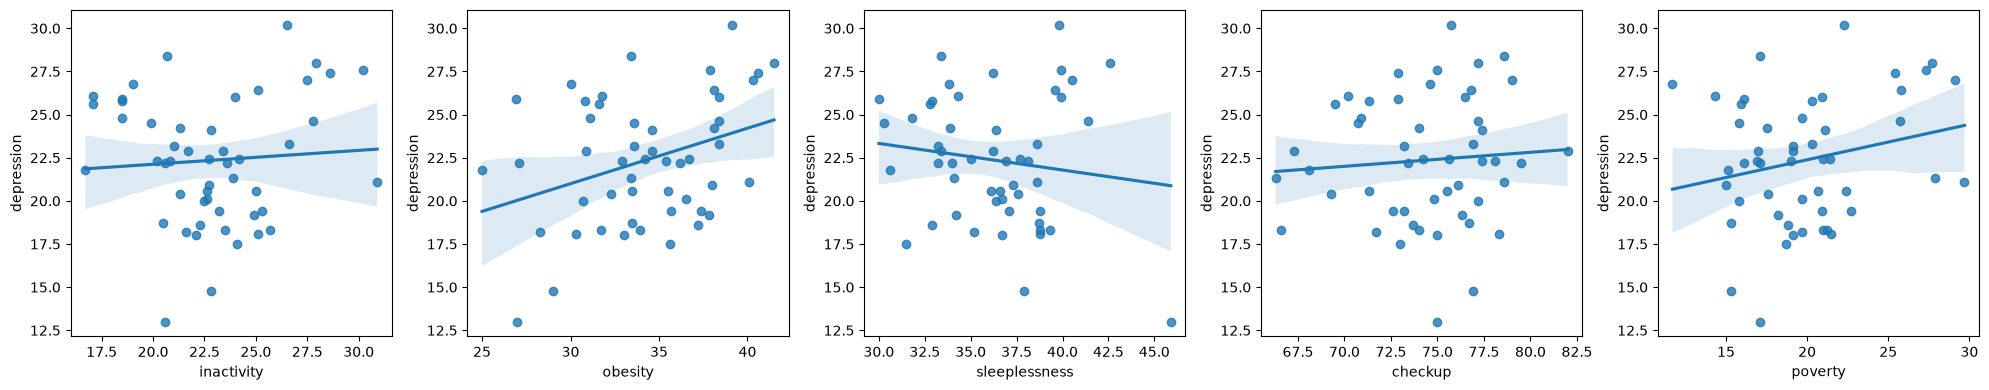

In [37]:
#Making scatterplots of our chosen predictors with their relation to depression
predictors = ['inactivity', 'obesity', 'sleeplessness', 'checkup', 'poverty']

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, p in zip(axes, predictors):
    sns.regplot(data=state_data, x=p, y='depression', ax=ax)
plt.tight_layout()
plt.show()

The result from the scatter plots shows us that there is no strong linear correlation with any of the variables with depression. Besides obesity and poverty, most of the graphs are near flat, meaning no relationship.

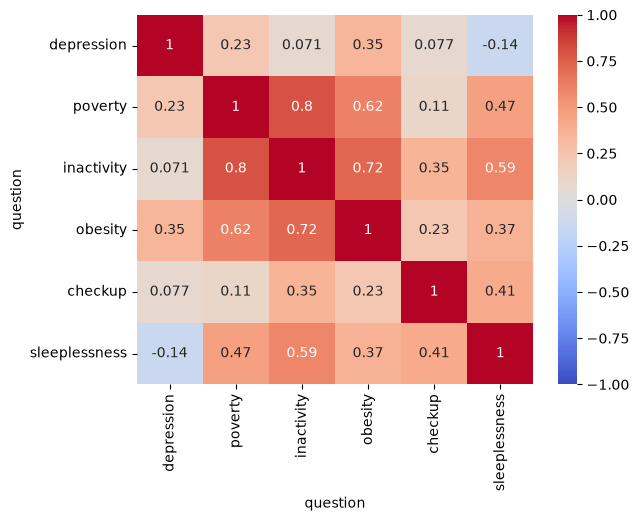

In [38]:
#Making a correlation heatmap for our variables
sns.heatmap(state_data.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

Our heatmap further reinforces our findings from the scatter plot showing that none of the predictors have strong linear correlation with depression. The highest being obesity with r = 0.35 and poverty with r = 0.23. These are weak relationships. There are also issues with multicollinearity. Inactivity has a strong correlation with poverty and obesity, with r = 0.8 and r = 0.72 respectively.

In [39]:
#Running a least squares regression with obesity being the chosen predictor, due to it having the highest r value
simple = smf.ols('depression ~ obesity', data=state_data).fit()
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:             depression   R-squared:                       0.119
Model:                            OLS   Adj. R-squared:                  0.101
Method:                 Least Squares   F-statistic:                     6.490
Date:                Thu, 29 Oct 2026   Prob (F-statistic):             0.0141
Time:                        16:16:33   Log-Likelihood:                -132.40
No. Observations:                  50   AIC:                             268.8
Df Residuals:                      48   BIC:                             272.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     11.3551      4.346      2.613      0.0

Obesity is a statistically significant predictor of depression at the state level (p = 0.014). However, obesity alone explains only about 10% of the variation in depression between states (adj. R² = 0.10). States with a 1-percentage-point higher obesity rate tend to have depression rates about 0.32 percentage points higher.

In [40]:
#Running a least squares regression with all our predictors.
model1 = smf.ols('depression ~ inactivity + obesity + sleeplessness + checkup + poverty', data=state_data).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:             depression   R-squared:                       0.328
Model:                            OLS   Adj. R-squared:                  0.251
Method:                 Least Squares   F-statistic:                     4.293
Date:                Thu, 29 Oct 2026   Prob (F-statistic):            0.00289
Time:                        16:16:33   Log-Likelihood:                -125.64
No. Observations:                  50   AIC:                             263.3
Df Residuals:                      44   BIC:                             274.8
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         4.9327     10.380      0.475

Our adj. R² = 0.25 is up from our 0.10 on obesity alone. It shows that the five predictors explain about 25% of the variation in depression between states. Holding the other predictors constant, our predictors poverty (p = 0.018, β = 0.48) and obesity (p = 0.004, β =  0.51) are both  positive and statistically significant. Sleeplessness and checkup rates were not significant. A red flag here is inactivity having a significant negative β (p = 0.017, β = -0.75). This is likely a result of multicollinearity as inactivity had a strong correlation with poverty (r = 0.80) and obesity (r = 0.72). 

# Model Diagnostics

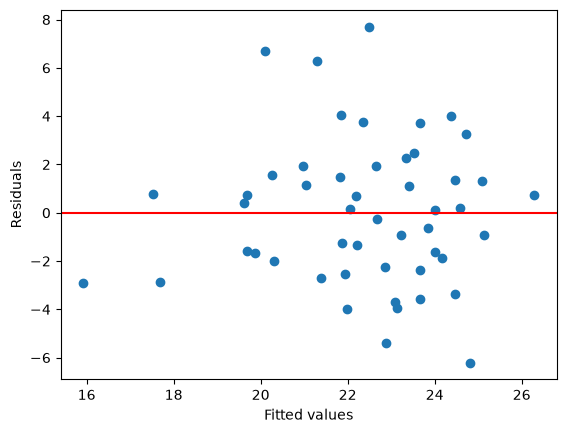

In [41]:
#Plotting a residuals vs fitted values to test for linearity
plt.scatter(model1.fittedvalues, model1.resid)
plt.axhline(0, color='red')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.show()

There is no clear pattern, and the residuals have a constant enough spread that suggests linearity and constant variance assumptions are reasonably met. There are some large residuals that we will test with Cook's distance.

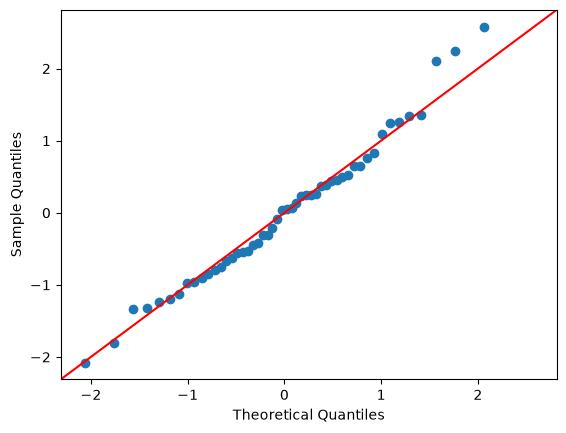

In [42]:
#Ploting a Q-Q plot to test residuals
sm.qqplot(model1.resid, line='45', fit=True)
plt.show()

The points follow the line closely, with slight deviation in the upper tail.  This supports the normality assumption.


In [43]:
#Running a VIF test for our predictors

X = sm.add_constant(state_data[predictors])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=predictors)
print(vif)

inactivity       4.704092
obesity          2.131353
sleeplessness    1.675815
checkup          1.371009
poverty          3.103632
dtype: float64


VIF measures predictor overlap. All our VIF values are under 5 so all our predictors are stable enough to stay. Inactivity has the highest, VIF = 4.7, meaning about 79% of its variation is explained by the other predictors, mainly poverty and obesity. This is consistent with its unexpected negative coefficient. Inactivity has the least reliable coefficient. The others have low VIFs so their estimates are stable.


In [44]:
#Cook's distance to test outlier influence
cook = pd.Series(model1.get_influence().cooks_distance[0], index=state_data.index)
print(cook.sort_values(ascending=False).head())

locationabbr
HI    0.187276
AR    0.139790
NH    0.103929
NE    0.082775
TN    0.075930
dtype: float64


The two thresholds most commonly used for Cook's distance are D > 4/n or  more conservatively D > 1. None of the values are over one. However, with the moderate threshold the cutoff would be 0.08. NE, NH, AR, and HI all surpass that. 

In [45]:
#Running a comparison without the most influential states to see how much the results change
model_cook = smf.ols('depression ~ inactivity + obesity + sleeplessness + checkup + poverty',
                       data=state_data.drop(['HI', 'AR', 'NH', 'NE'])).fit()

comparison = pd.DataFrame({'coeff full': model1.params, 'coeff cook': model_cook.params,
                           'p full': model1.pvalues, 'p cook': model_cook.pvalues})
print(comparison.round(3))

               coeff full  coeff cook  p full  p cook
Intercept           4.933       4.652   0.637   0.623
inactivity         -0.750      -0.898   0.017   0.004
obesity             0.513       0.537   0.004   0.001
sleeplessness      -0.343      -0.295   0.060   0.171
checkup             0.267       0.268   0.085   0.058
poverty             0.483       0.532   0.018   0.006


No major changes occurred after removing the four most influential states. No predictors changed in significance and no coefficients changed drastically. Inactivity is still negative showing that outliers did not cause its negative coefficient. We will draw conclusions using our least squares regression that used all the predictors and all the states.

In [46]:
#Exporting data for tableau
state_data.reset_index()
state_data.to_csv('state_data_2022.csv')
national_depression.to_csv('national_data.csv')
